# Water sorption diagnostics

Pick one test (or several), load its HFR-fit and E-cell-fit results, run the DAE to the
last simulated cell state, and inspect membrane water content (lambda) and anode water
sorption (vapor concentration, liquid saturation).

**Workflow:** edit the *Parameters* cell -> run all -> read the plots.
Set `TEST_CONFIGS` to a list of `(test_no, mode)` pairs -- one entry to inspect a single
test, or several to run them back to back and compare (e.g. the highest-discharge test
against the highest-charge test). `J_INDEX = -1` always picks the highest-|current| point
for each test's chosen mode.


In [ ]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import json
from solve_dae.integrate import solve_dae
ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "Experimental"))
from simulate_HFR import build_cell, build_atol, soc_cutoff_event
from rfbmodel1D.parameters.params import membraneparams, SimulationParams, Vars, cellparams, cathodeparams, anodeparams


## -- Parameters --


In [2]:
# -- test / point selection -----------------------------------------------------
# list of (test_no, mode) pairs -- each test can use its own mode, e.g. the
# highest-discharge test paired with the highest-charge test.
TEST_CONFIGS = [(5, "discharge"), (25, "charge")]
J_INDEX = -1   # index into that test's current-density list for its mode (0-based, -1 = highest |j|)

# tests to sweep over their full charge+discharge current-density range (flux-vs-j plot below)
FLUX_SWEEP_TESTS = [5, 16, 25]

# -- solver settings --------------------------------------------------------------
TF   = 1800
RTOL = 1e-5


## Load fits and simulate each test to its final (last) cell state


In [3]:
runs = {}

for TEST_NO, MODE in TEST_CONFIGS:
    print(f"\n=== Test {TEST_NO} ({MODE}) ===")

    # -- fit results --------------------------------------------------------------
    FIT_DIR    = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
    HFR_FIT    = sorted(FIT_DIR.glob(f"fit_v2_test{TEST_NO}_*.json"))[-1].name
    E_CELL_FIT = sorted(FIT_DIR.glob(f"fit_e_cell_test{TEST_NO}_*.json"))[-1].name

    # -- apply HFR membrane params --------------------------------------------------
    with open(FIT_DIR / HFR_FIT) as f:
        _hfr = json.load(f)
    _p, _s = _hfr["params"], _hfr["settings"]
    membraneparams.k_sorp_vw   = _p["k_vw_sorp"]
    membraneparams.k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = _p["k_lw_sorp"]
    membraneparams.k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"]
    membraneparams.k_ca_lw     = _p["k_ca"]
    membraneparams.sf_D        = _s["sf_D"]
    cellparams.vanadium_uptake = _s["vanadium_uptake"]
    R_EXTRA = _p["R_extra (Ω·cm²)"] / 1e4
    print(f"HFR membrane params loaded from: {HFR_FIT}")

    # -- apply E-cell kinetic params ------------------------------------------------
    with open(FIT_DIR / E_CELL_FIT) as f:
        _ec = json.load(f)
    k_ca  = _ec["params"]["k_ca"]
    j0_an = _ec["params"]["j0_an"]
    cathodeparams.reaction_rate_constant = k_ca
    anodeparams.j_0                      = j0_an
    print(f"E-cell params loaded from: {E_CELL_FIT}")
    print(f"k_ca = {k_ca:.4e} m/s   j0_an = {j0_an:.4e} A/m²")

    # -- load the matching experimental point --------------------------------------
    hfr_df = pd.read_csv(ROOT / "data" / "experimental" / "HFR.csv")
    hfr_df = hfr_df[(hfr_df["test_no"] == TEST_NO) & (hfr_df["mode"] == MODE)]
    soc = hfr_df["SOC"].iloc[0]
    T   = hfr_df["T(°C)"].iloc[0]
    Q_v = hfr_df["Q_v (ml/min)"].iloc[0]
    j_appl_raw = float(hfr_df["j_appl (A/m2)"].values[J_INDEX])
    j_appl     = j_appl_raw if MODE == "charge" else -j_appl_raw
    HFR_exp    = float(hfr_df["value (ohm cm2)"].values[J_INDEX])

    # E_cell.csv has its own (differently spaced) current grid, so interpolate
    # at j_appl_raw rather than reusing J_INDEX across the two files.
    e_df = pd.read_csv(ROOT / "data" / "experimental" / "E_cell.csv")
    e_df = e_df[(e_df["test_no"] == TEST_NO) & (e_df["mode"] == MODE)].sort_values("j_appl (A/m2)")
    E_exp = float(np.interp(j_appl_raw, e_df["j_appl (A/m2)"].values, e_df["value (V)"].values))

    print(f"SOC={soc}, T={T}°C, Q_v={Q_v} ml/min  |  j_appl={j_appl:+.0f} A/m²  "
          f"|  HFR_exp={HFR_exp:.4f} Ω·cm²  |  E_exp={E_exp:.4f} V")

    # -- simulate to the last cell state --------------------------------------------
    cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
    atol          = build_atol(cell)
    jac_sparsity  = cell.compute_jac_sparsity(y0, yp0)

    t0_wall = time.time()
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    elapsed = time.time() - t0_wall
    print(f"✓ Done in {elapsed:.1f} s  |  {len(sol.t)} time points  |  "
          f"reached t={sol.t[-1]:.1f} s  |  success={sol.success}  |  {sol.message}")

    runs[TEST_NO] = dict(
        cell=cell, tsol=sol.t, ysol=sol.y, success=sol.success,
        mode=MODE, soc=soc, T=T, Q_v=Q_v, j_appl=j_appl,
        HFR_exp=HFR_exp, E_exp=E_exp, R_EXTRA=R_EXTRA,
    )

print(f"\nFinished {len(runs)} test(s): {list(runs.keys())}")



=== Test 5 (discharge) ===
HFR membrane params loaded from: fit_v2_test5_20260613_185943.json
E-cell params loaded from: fit_e_cell_test5_20260614_000424.json
k_ca = 1.0961e-06 m/s   j0_an = 1.3634e+03 A/m²
SOC=0.1, T=32°C, Q_v=45 ml/min  |  j_appl=-2023 A/m²  |  HFR_exp=0.9240 Ω·cm²  |  E_exp=0.7663 V
✓ Done in 2.2 s  |  60 time points  |  reached t=1800.0 s  |  success=True  |  The solver successfully reached the end of the integration interval.

=== Test 25 (charge) ===
HFR membrane params loaded from: fit_v2_test25_20260619_131922.json
E-cell params loaded from: fit_e_cell_test25_20260616_012720.json
k_ca = 1.0961e-06 m/s   j0_an = 1.5238e+03 A/m²
SOC=0.9, T=32°C, Q_v=45 ml/min  |  j_appl=+1994 A/m²  |  HFR_exp=0.5351 Ω·cm²  |  E_exp=1.3758 V
✓ Done in 11.3 s  |  99 time points  |  reached t=1800.0 s  |  success=True  |  The solver successfully reached the end of the integration interval.

Finished 2 test(s): [5, 25]


## HFR & E-cell sanity check (simulated vs. experimental, at the last cell state)


In [4]:
for TEST_NO, r in runs.items():
    cell, ysol = r["cell"], r["ysol"]

    kappa_io_ca = cell.cathode.kappa_io
    sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
    dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    R_cathode   = float(np.sum(dx_ca / (sigma_ca + kappa_io_ca)))

    kappa_io_m = cell.membrane.kappa_io
    dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane = float(np.sum(dx_m / kappa_io_m))

    R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC

    HFR_sim = (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC + r["R_EXTRA"]) * 1e4

    Nc      = cell.mesh.cathode_mesh.n_x
    n_ca    = cell.layout.n_vars_cathode
    off_ca  = cell.layout.n_vars_tank
    Phi_el  = ysol[off_ca:off_ca + Nc * n_ca, -1].reshape(Nc, n_ca)[:, 4]
    dx0     = cell.mesh.cathode_mesh.dx[0] * cell.cathode.thickness
    E_sim   = float(Phi_el[0] + r["j_appl"] * (dx0 / 2) / cell.cathode.eff_conductivity)

    print(f"Test {TEST_NO}: HFR sim={HFR_sim:.4f}  exp={r['HFR_exp']:.4f}  "
          f"(err {HFR_sim - r['HFR_exp']:+.4f} Ω·cm²)   |   "
          f"E sim={E_sim:.4f}  exp={r['E_exp']:.4f} V  (err {E_sim - r['E_exp']:+.4f} V)")


Test 5: HFR sim=0.9689  exp=0.9240  (err +0.0449 Ω·cm²)   |   E sim=0.7579  exp=0.7663 V  (err -0.0084 V)
Test 25: HFR sim=0.5280  exp=0.5351  (err -0.0071 Ω·cm²)   |   E sim=1.3864  exp=1.3758 V  (err +0.0106 V)


## Extract membrane & anode water-content variables


In [5]:
for TEST_NO, r in runs.items():
    cell = r["cell"]
    Nc     = cell.mesh.cathode_mesh.n_x
    Nm     = cell.mesh.membrane_mesh.n_x
    n_tank = cell.layout.n_vars_tank
    n_ca   = cell.layout.n_vars_cathode
    n_mem  = cell.layout.n_vars_membrane
    n_an   = cell.layout.n_vars_anode

    off_ca  = n_tank
    off_mem = off_ca + Nc * n_ca
    off_an  = off_mem + Nm * n_mem

    y_mem_all = r["ysol"][off_mem:off_an, :].reshape(Nm, n_mem, -1)   # (Nm, n_mem, Nt)
    y_an_all  = r["ysol"][off_an:off_an + n_an, :]                    # (n_an, Nt)

    r["lambda_mem"] = y_mem_all[:, 0, :]    # (Nm, Nt)
    r["c_vw_acl"]   = y_an_all[0, :]
    r["c_H2_acl"]   = y_an_all[1, :]
    r["s_acl"]      = y_an_all[2, :]
    r["eta_acl"]    = y_an_all[3, :]
    r["c_vw_agdl"]  = y_an_all[4, :]
    r["c_H2_agdl"]  = y_an_all[5, :]
    r["s_agdl"]     = y_an_all[6, :]

    # normalised membrane coordinate, 0 = cathode side, 1 = anode side
    edges_m = np.concatenate([[0.0], np.cumsum(cell.mesh.membrane_mesh.dx)])
    r["x_mem_norm"] = 0.5 * (edges_m[:-1] + edges_m[1:])


## Water-sorption time evolution (overlaid across selected tests)


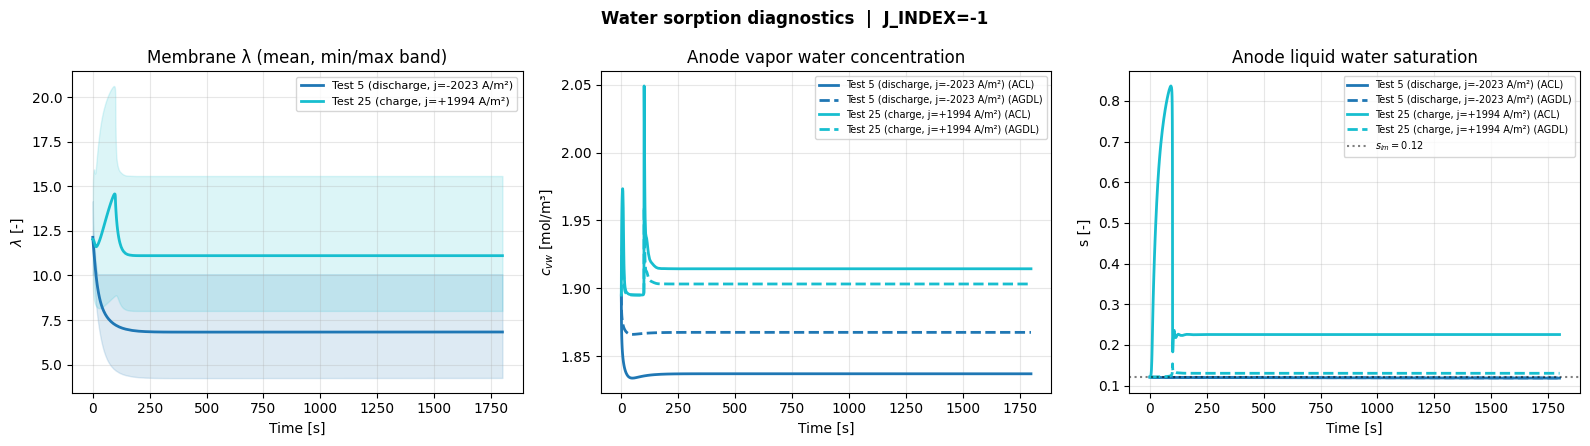

In [6]:
colors = plt.cm.tab10(np.linspace(0, 1, max(len(runs), 2)))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for (TEST_NO, r), c in zip(runs.items(), colors):
    lam = r["lambda_mem"]
    lam_mean, lam_min, lam_max = lam.mean(axis=0), lam.min(axis=0), lam.max(axis=0)
    label = f"Test {TEST_NO} ({r['mode']}, j={r['j_appl']:+.0f} A/m²)"

    axes[0].plot(r["tsol"], lam_mean, lw=2, color=c, label=label)
    axes[0].fill_between(r["tsol"], lam_min, lam_max, alpha=0.15, color=c)

    axes[1].plot(r["tsol"], r["c_vw_acl"],  lw=2, color=c, label=f"{label} (ACL)")
    axes[1].plot(r["tsol"], r["c_vw_agdl"], lw=2, color=c, ls="--", label=f"{label} (AGDL)")

    axes[2].plot(r["tsol"], r["s_acl"],  lw=2, color=c, label=f"{label} (ACL)")
    axes[2].plot(r["tsol"], r["s_agdl"], lw=2, color=c, ls="--", label=f"{label} (AGDL)")

axes[0].set_title("Membrane λ (mean, min/max band)")
axes[0].set_xlabel("Time [s]"); axes[0].set_ylabel(r"$\lambda$ [-]")
axes[0].grid(True, alpha=0.3); axes[0].legend(fontsize=8)

axes[1].set_title("Anode vapor water concentration")
axes[1].set_xlabel("Time [s]"); axes[1].set_ylabel(r"$c_{vw}$ [mol/m³]")
axes[1].grid(True, alpha=0.3); axes[1].legend(fontsize=7)

axes[2].axhline(0.12, color="k", ls=":", alpha=0.5, label=r"$s_{im}=0.12$")
axes[2].set_title("Anode liquid water saturation")
axes[2].set_xlabel("Time [s]"); axes[2].set_ylabel("s [-]")
axes[2].grid(True, alpha=0.3); axes[2].legend(fontsize=7)

fig.suptitle(f"Water sorption diagnostics  |  J_INDEX={J_INDEX}", fontweight="bold")
fig.tight_layout()
plt.show()


## Membrane -> anode water flux vs. applied current density

For each test in `FLUX_SWEEP_TESTS`, sweep every charge/discharge current-density point
in `HFR.csv`, run each to steady state, and decompose the membrane->anode flux at the
last internal membrane face into its diffusive and electro-osmotic-drag (EOD)
contributions -- the same two terms that make up `N_w` in `water_transport_residual.py`.


In [7]:
flux_sweep = {}

for TEST_NO in FLUX_SWEEP_TESTS:
    print(f"\n=== Flux sweep: test {TEST_NO} ===")

    # -- apply this test's fits ----------------------------------------------------
    FIT_DIR    = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
    HFR_FIT    = sorted(FIT_DIR.glob(f"fit_v2_test{TEST_NO}_*.json"))[-1].name
    E_CELL_FIT = sorted(FIT_DIR.glob(f"fit_e_cell_test{TEST_NO}_*.json"))[-1].name

    with open(FIT_DIR / HFR_FIT) as f:
        _hfr = json.load(f)
    _p, _s = _hfr["params"], _hfr["settings"]
    membraneparams.k_sorp_vw   = _p["k_vw_sorp"]
    membraneparams.k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = _p["k_lw_sorp"]
    membraneparams.k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"]
    membraneparams.k_ca_lw     = _p["k_ca"]
    membraneparams.sf_D        = _s["sf_D"]
    cellparams.vanadium_uptake = _s["vanadium_uptake"]

    with open(FIT_DIR / E_CELL_FIT) as f:
        _ec = json.load(f)
    cathodeparams.reaction_rate_constant = _ec["params"]["k_ca"]
    anodeparams.j_0                      = _ec["params"]["j0_an"]

    # -- full charge+discharge current grid for this test ---------------------------
    hfr_df = pd.read_csv(ROOT / "data" / "experimental" / "HFR.csv")
    hfr_df = hfr_df[hfr_df["test_no"] == TEST_NO]
    soc = hfr_df["SOC"].iloc[0]
    T   = hfr_df["T(°C)"].iloc[0]
    Q_v = hfr_df["Q_v (ml/min)"].iloc[0]

    j_charge    =  hfr_df[hfr_df["mode"] == "charge"]["j_appl (A/m2)"].values
    j_discharge = -hfr_df[hfr_df["mode"] == "discharge"]["j_appl (A/m2)"].values
    j_all = np.concatenate([j_charge, j_discharge])

    J_diff_ca_list, J_EOD_ca_list, J_total_ca_list = [], [], []
    J_diff_an_list, J_EOD_an_list, J_total_an_list = [], [], []
    lambda_ca_list, lambda_eq_corr_list = [], []
    lambda_an_list, lambda_eq_an_list = [], []
    Nw_over_iF_ca_list, Nw_over_iF_an_list = [], []
    for j_appl in j_all:
        cell, y0, yp0 = build_cell(soc, j_appl, T, Q_v)
        atol         = build_atol(cell)
        jac_sparsity = cell.compute_jac_sparsity(y0, yp0)
        sol = solve_dae(
            cell.dae_residual_full_cell,
            (0.0, TF), y0, yp0,
            method="BDF", atol=atol, rtol=RTOL,
            events=soc_cutoff_event, jac_sparsity=jac_sparsity,
        )

        Nc, Nm = cell.mesh.cathode_mesh.n_x, cell.mesh.membrane_mesh.n_x
        n_tank = cell.layout.n_vars_tank
        n_ca   = cell.layout.n_vars_cathode
        n_mem  = cell.layout.n_vars_membrane
        off_mem = n_tank + Nc * n_ca
        off_an  = off_mem + Nm * n_mem
        lam_last = sol.y[off_mem:off_an, -1].reshape(Nm, n_mem)[:, 0]

        dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
        edges_m    = np.concatenate([[0.0], np.cumsum(dx_m)])
        x_center_m = 0.5 * (edges_m[:-1] + edges_m[1:])

        F, c_f = cell.F, cell.membrane.c_f

        # -- cathode-side face (x_1, between node 0 and node 1) -------------------------
        # Upwind choice matches the LEFT boundary in dae_residual_full_cell.py
        # (lines ~396-401): for i_io>0 (current flowing cathode->anode) the
        # upstream/cathode-ward node is lam[0]; otherwise lam[1].
        dx_face_ca    = x_center_m[1] - x_center_m[0]
        D_face_ca     = cell.membrane_water_diffusivity((lam_last[0] + lam_last[1]) / 2, "hwang")
        lam_upwind_ca = lam_last[0] if j_appl > 0 else lam_last[1]
        zeta_face_ca  = cell.EOD_coefficient(lam_upwind_ca)
        J_diff_ca = float(-c_f * D_face_ca * (lam_last[1] - lam_last[0]) / dx_face_ca)
        J_EOD_ca  = float(zeta_face_ca * j_appl / F)

        # -- anode-side face (x_N, between the last two nodes) ---------------------------
        # Upwind choice matches the RIGHT boundary in dae_residual_full_cell.py
        # (lines ~413-419): for i_io>0 the upstream/cathode-ward node of the pair
        # is lam[-2]; otherwise lam[-1].
        dx_face_an    = x_center_m[-1] - x_center_m[-2]
        D_face_an     = cell.membrane_water_diffusivity((lam_last[-1] + lam_last[-2]) / 2, "hwang")
        lam_upwind_an = lam_last[-2] if j_appl > 0 else lam_last[-1]
        zeta_face_an  = cell.EOD_coefficient(lam_upwind_an)
        J_diff_an = float(-c_f * D_face_an * (lam_last[-1] - lam_last[-2]) / dx_face_an)
        J_EOD_an  = float(zeta_face_an * j_appl / F)

        J_diff_ca_list.append(J_diff_ca); J_EOD_ca_list.append(J_EOD_ca); J_total_ca_list.append(J_diff_ca + J_EOD_ca)
        J_diff_an_list.append(J_diff_an); J_EOD_an_list.append(J_EOD_an); J_total_an_list.append(J_diff_an + J_EOD_an)

        # -- water-to-proton drag ratio N_w/(i/F) at both faces -------------------------
        # j_appl == i_io at steady state (no current sink/source across the membrane),
        # so i/F = j_appl/F is the molar proton flux through both faces.
        i_over_F = j_appl / F
        Nw_over_iF_ca_list.append((J_diff_ca + J_EOD_ca) / i_over_F)
        Nw_over_iF_an_list.append((J_diff_an + J_EOD_an) / i_over_F)

        # -- boundary water contents vs. their equilibrium targets ----------------------
        # Re-evaluate the residual at the converged final state so self.bc gets
        # refreshed exactly like it is during the solve (see update_BC_cathode_membrane
        # and update_BC_membrane_anode in dae_residual_full_cell.py), then read off the
        # water-activity BCs at both interfaces.
        cell.dae_residual_full_cell(sol.t[-1], sol.y[:, -1], np.zeros_like(sol.y[:, -1]))

        a_left            = cell.bc[Vars.a]["membrane"]["left"].value
        lambda_eq_ca       = cell.return_lambda_cath_eq(a_left)
        lambda_eq_ca_corr  = cell.return_lambda_corr(lambda_eq_ca)
        lambda_ca_list.append(float(lam_last[0]))
        lambda_eq_corr_list.append(float(lambda_eq_ca_corr))

        a_right      = cell.bc[Vars.a]["membrane"]["right"].value
        lambda_eq_an  = cell.return_lambda_eq(a_right)
        if lambda_eq_an < 2.01:
            lambda_eq_an = 2.01   # minimum water content, matches dae_residual_full_cell.py line ~382
        lambda_an_list.append(float(lam_last[-1]))
        lambda_eq_an_list.append(float(lambda_eq_an))

        print(f"  j={j_appl:+7.0f} A/m²  |  success={sol.success}  |  "
              f"ca: J_diff={J_diff_ca*1e3:+7.4f} J_EOD={J_EOD_ca*1e3:+7.4f}  |  "
              f"an: J_diff={J_diff_an*1e3:+7.4f} J_EOD={J_EOD_an*1e3:+7.4f}  |  "
              f"Nw/(i/F): ca={Nw_over_iF_ca_list[-1]:+.4f}  an={Nw_over_iF_an_list[-1]:+.4f}  |  "
              f"λ(x_1)={lam_last[0]:.3f}  λ_eq,ca^corr={lambda_eq_ca_corr:.3f}  |  "
              f"λ(x_N)={lam_last[-1]:.3f}  λ_eq,an={lambda_eq_an:.3f}")

    flux_sweep[TEST_NO] = dict(
        j=np.asarray(j_all),
        J_diff_ca=np.asarray(J_diff_ca_list),
        J_EOD_ca=np.asarray(J_EOD_ca_list),
        J_total_ca=np.asarray(J_total_ca_list),
        J_diff_an=np.asarray(J_diff_an_list),
        J_EOD_an=np.asarray(J_EOD_an_list),
        J_total_an=np.asarray(J_total_an_list),
        Nw_over_iF_ca=np.asarray(Nw_over_iF_ca_list),
        Nw_over_iF_an=np.asarray(Nw_over_iF_an_list),
        lambda_ca=np.asarray(lambda_ca_list),
        lambda_eq_corr=np.asarray(lambda_eq_corr_list),
        lambda_an=np.asarray(lambda_an_list),
        lambda_eq_an=np.asarray(lambda_eq_an_list),
    )

print(f"\nFlux sweep finished for tests: {list(flux_sweep.keys())}")



=== Flux sweep: test 5 ===
  j=    +35 A/m²  |  success=True  |  ca: J_diff=-4.1485 J_EOD=+0.4127  |  an: J_diff=-4.2383 J_EOD=+0.5009  |  Nw/(i/F): ca=-10.3328  an=-10.3374  |  λ(x_1)=10.046  λ_eq,ca^corr=10.044  |  λ(x_N)=12.237  λ_eq,an=13.650
  j=   +314 A/m²  |  success=True  |  ca: J_diff=-5.5779 J_EOD=+3.7132  |  an: J_diff=-6.7593 J_EOD=+4.8737  |  Nw/(i/F): ca=-0.5731  an=-0.5795  |  λ(x_1)=10.042  λ_eq,ca^corr=10.042  |  λ(x_N)=13.252  λ_eq,an=13.897
  j=   +500 A/m²  |  success=True  |  ca: J_diff=-6.3831 J_EOD=+5.9122  |  an: J_diff=-8.6634 J_EOD=+8.1519  |  Nw/(i/F): ca=-0.0909  an=-0.0987  |  λ(x_1)=10.040  λ_eq,ca^corr=10.040  |  λ(x_N)=13.935  λ_eq,an=14.059
  j=   +756 A/m²  |  success=True  |  ca: J_diff=-7.8416 J_EOD=+8.9342  |  an: J_diff=-12.4313 J_EOD=+13.4424  |  Nw/(i/F): ca=+0.1395  an=+0.1291  |  λ(x_1)=10.037  λ_eq,ca^corr=10.037  |  λ(x_N)=15.233  λ_eq,an=14.904
  j=  +1012 A/m²  |  success=True  |  ca: J_diff=-8.1694 J_EOD=+11.9540  |  an: J_diff=-15.1252 

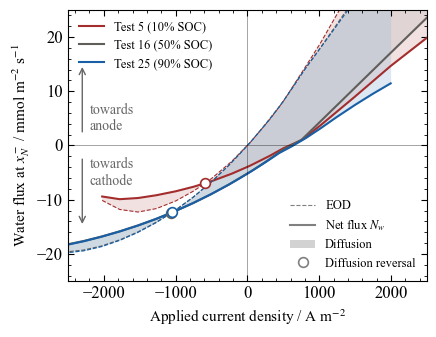

In [8]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import numpy as np

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

custom = LinearSegmentedColormap.from_list("soc", ['#A32D2D', '#5F5E5A', '#185FA5'])
soc_colors = custom(np.linspace(0.0, 1.0, len(flux_sweep)))
test_labels = {5: "10% SOC", 16: "50% SOC", 25: "90% SOC"}

def lighten(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    return tuple(c + (1 - c) * amount)

def find_zero_diffusion(j_sorted, eod, total):
    """Find j values where diffusion (= total - eod) crosses zero, via linear interpolation."""
    diff = total - eod
    sign_changes = np.where(np.diff(np.sign(diff)) != 0)[0]
    crossings = []
    for i in sign_changes:
        j_cross = j_sorted[i] - diff[i] * (j_sorted[i+1] - j_sorted[i]) / (diff[i+1] - diff[i])
        flux_cross = eod[i] + (eod[i+1] - eod[i]) * (j_cross - j_sorted[i]) / (j_sorted[i+1] - j_sorted[i])
        crossings.append((j_cross, flux_cross))
    return crossings

fig, ax = plt.subplots(figsize=(4.5, 3.5))

zero_diff_points = []

for (TEST_NO, d), c in zip(flux_sweep.items(), soc_colors):
    order    = np.argsort(d["j"])
    j_sorted = d["j"][order]
    eod   = d["J_EOD_an"][order]   * 1e3
    total = d["J_total_an"][order] * 1e3
    c_light = lighten(c, 0.6)
    
    ax.fill_between(j_sorted, eod, total, color=c_light, alpha=0.35, linewidth=0)
    ax.plot(j_sorted, eod,   lw=0.8, color=c, ls="--")
    ax.plot(j_sorted, total, lw=1.5, color=c, ls="-")
    
    crossings = find_zero_diffusion(j_sorted, eod, total)
    for j_cross, flux_cross in crossings:
        zero_diff_points.append((j_cross, flux_cross, c))

for j_cross, flux_cross, c in zero_diff_points:
    ax.plot(j_cross, flux_cross, 'o', color=c,
            markerfacecolor='white', markeredgewidth=1.2,
            markersize=7, zorder=10)

ax.axhline(0, color="k", lw=0.5, alpha=0.5)
ax.axvline(0, color="k", lw=0.5, alpha=0.5)
ax.set_xlabel(r"Applied current density / A m$^{-2}$")
ax.set_ylabel(r"Water flux at $x_N^-$ / mmol m$^{-2}$ s$^{-1}$")
ax.set_xlim(-2500, 2500)
ax.set_ylim(-25, 25)

ax.annotate('', xy=(-2300, 15), xytext=(-2300, 2),
            arrowprops=dict(arrowstyle='->', color='0.4', lw=1.0))
ax.text(-2200, 5, "towards\nanode", fontsize=10, color='0.4',
        va='center', ha='left')

ax.annotate('', xy=(-2300, -15), xytext=(-2300, -2),
            arrowprops=dict(arrowstyle='->', color='0.4', lw=1.0))
ax.text(-2200, -5, "towards\ncathode", fontsize=10, color='0.4',
        va='center', ha='left')

test_handles = [Line2D([0],[0], color=c, lw=1.5, label=f"Test {t} ({test_labels[t]})")
                for c, t in zip(soc_colors, flux_sweep.keys())]
style_handles = [
    Line2D([0],[0], color='gray', lw=0.8, ls='--', label='EOD'),
    Line2D([0],[0], color='gray', lw=1.5, ls='-',  label=r'Net flux $N_w$'),
    Patch(facecolor='gray', alpha=0.35, label='Diffusion'),
    Line2D([0],[0], color='gray', marker='o', markerfacecolor='white',
           markeredgewidth=1.2, markersize=7, ls='', label='Diffusion reversal'),
]
leg1 = ax.legend(handles=test_handles, loc='upper left', frameon=False)
ax.add_artist(leg1)
ax.legend(handles=style_handles, loc='lower right', frameon=False)

plt.tight_layout()
out_path = ROOT / "figures/flux_balance_anode.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()

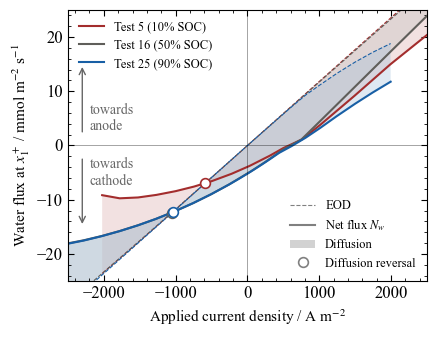

In [9]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import numpy as np

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 11,
    'axes.labelsize': 11,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 9,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

custom = LinearSegmentedColormap.from_list("soc", ['#A32D2D', '#5F5E5A', '#185FA5'])
soc_colors = custom(np.linspace(0.0, 1.0, len(flux_sweep)))
test_labels = {5: "10% SOC", 16: "50% SOC", 25: "90% SOC"}

def lighten(color, amount=0.5):
    c = np.array(mcolors.to_rgb(color))
    return tuple(c + (1 - c) * amount)

def find_zero_diffusion(j_sorted, eod, total):
    """Find j values where diffusion (= total - eod) crosses zero, via linear interpolation."""
    diff = total - eod
    sign_changes = np.where(np.diff(np.sign(diff)) != 0)[0]
    crossings = []
    for i in sign_changes:
        j_cross = j_sorted[i] - diff[i] * (j_sorted[i+1] - j_sorted[i]) / (diff[i+1] - diff[i])
        flux_cross = eod[i] + (eod[i+1] - eod[i]) * (j_cross - j_sorted[i]) / (j_sorted[i+1] - j_sorted[i])
        crossings.append((j_cross, flux_cross))
    return crossings

fig, ax = plt.subplots(figsize=(4.5, 3.5))

zero_diff_points = []

for (TEST_NO, d), c in zip(flux_sweep.items(), soc_colors):
    order    = np.argsort(d["j"])
    j_sorted = d["j"][order]
    eod   = d["J_EOD_ca"][order]   * 1e3
    total = d["J_total_ca"][order] * 1e3
    c_light = lighten(c, 0.6)
    
    ax.fill_between(j_sorted, eod, total, color=c_light, alpha=0.35, linewidth=0)
    ax.plot(j_sorted, eod,   lw=0.8, color=c, ls="--")
    ax.plot(j_sorted, total, lw=1.5, color=c, ls="-")
    
    crossings = find_zero_diffusion(j_sorted, eod, total)
    for j_cross, flux_cross in crossings:
        zero_diff_points.append((j_cross, flux_cross, c))

for j_cross, flux_cross, c in zero_diff_points:
    ax.plot(j_cross, flux_cross, 'o', color=c,
            markerfacecolor='white', markeredgewidth=1.2,
            markersize=7, zorder=10)

ax.axhline(0, color="k", lw=0.5, alpha=0.5)
ax.axvline(0, color="k", lw=0.5, alpha=0.5)
ax.set_xlabel(r"Applied current density / A m$^{-2}$")
ax.set_ylabel(r"Water flux at $x_1^+$ / mmol m$^{-2}$ s$^{-1}$")
ax.set_xlim(-2500, 2500)
ax.set_ylim(-25, 25)

ax.annotate('', xy=(-2300, 15), xytext=(-2300, 2),
            arrowprops=dict(arrowstyle='->', color='0.4', lw=1.0))
ax.text(-2200, 5, "towards\nanode", fontsize=10, color='0.4',
        va='center', ha='left')

ax.annotate('', xy=(-2300, -15), xytext=(-2300, -2),
            arrowprops=dict(arrowstyle='->', color='0.4', lw=1.0))
ax.text(-2200, -5, "towards\ncathode", fontsize=10, color='0.4',
        va='center', ha='left')

test_handles = [Line2D([0],[0], color=c, lw=1.5, label=f"Test {t} ({test_labels[t]})")
                for c, t in zip(soc_colors, flux_sweep.keys())]
style_handles = [
    Line2D([0],[0], color='gray', lw=0.8, ls='--', label='EOD'),
    Line2D([0],[0], color='gray', lw=1.5, ls='-',  label=r'Net flux $N_w$'),
    Patch(facecolor='gray', alpha=0.35, label='Diffusion'),
    Line2D([0],[0], color='gray', marker='o', markerfacecolor='white',
           markeredgewidth=1.2, markersize=7, ls='', label='Diffusion reversal'),
]
leg1 = ax.legend(handles=test_handles, loc='upper left', frameon=False)
ax.add_artist(leg1)
ax.legend(handles=style_handles, loc='lower right', frameon=False)

plt.tight_layout()
out_path = ROOT / "figures/flux_balance_cathode.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()


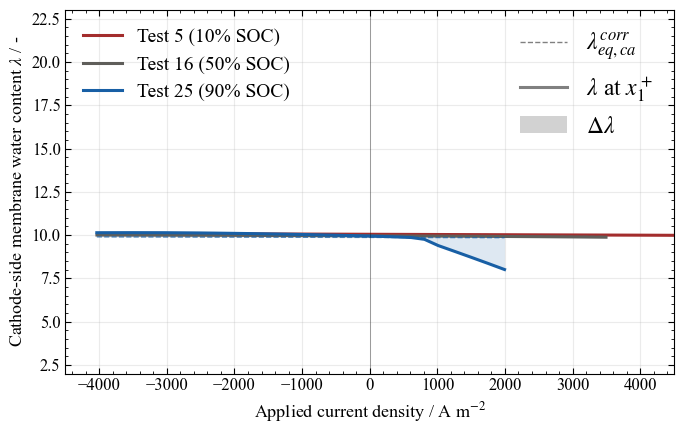

In [10]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import numpy as np


plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

custom = LinearSegmentedColormap.from_list("soc", ['#A32D2D', '#5F5E5A', '#185FA5'])
soc_colors = custom(np.linspace(0.0, 1.0, len(flux_sweep)))
test_labels = {5: "10% SOC", 16: "50% SOC", 25: "90% SOC"}

def lighten(color, amount=0.6):
    c = np.array(mcolors.to_rgb(color))
    return tuple(c + (1 - c) * amount)

fig, ax = plt.subplots(figsize=(7, 4.5))

for (TEST_NO, d), c in zip(flux_sweep.items(), soc_colors):
    order        = np.argsort(d["j"])
    j_sorted     = d["j"][order]
    lambda_b     = d["lambda_ca"][order]       # boundary λ
    lambda_eq    = d["lambda_eq_corr"][order]  # equilibrium λ at cathode
    c_light      = lighten(c, 0.6)
    
    ax.fill_between(j_sorted, lambda_b, lambda_eq, color=c_light, alpha=0.35, linewidth=0)
    ax.plot(j_sorted, lambda_eq, lw=1.0, color=c, ls="--", alpha=0.7)
    ax.plot(j_sorted, lambda_b,  lw=2.2, color=c, ls="-")

ax.axvline(0, color="k", lw=0.6, alpha=0.4)
ax.set_xlabel(r"Applied current density / A m$^{-2}$")
ax.set_ylabel(r"Cathode-side membrane water content $\lambda$ / -")
ax.grid(True, alpha=0.25)
ax.set_xlim(-4500, 4500)
#ax.set_ylim(7.5, 10.5)
ax.set_ylim(2, 23)

test_handles = [Line2D([0],[0], color=c, lw=2.2, label=f"Test {t} ({test_labels[t]})")
                for c, t in zip(soc_colors, flux_sweep.keys())]
style_handles = [
    Line2D([0],[0], color='gray', lw=1.0, ls='--', label=r'$\lambda_{eq,ca}^{corr}$'),
    Line2D([0],[0], color='gray', lw=2.2, ls='-',  label=r'$\lambda$ at $x_1^+$'),
    Patch(facecolor='gray', alpha=0.35, label=r'$\Delta\lambda$'),
]
leg1 = ax.legend(handles=test_handles, loc='upper left', fontsize=14, frameon=False)
ax.add_artist(leg1)
ax.legend(handles=style_handles, loc='upper right', fontsize=17, frameon=False)

plt.tight_layout()
out_path = ROOT / f"figures/boundary_membrane_ca.pdf"
plt.savefig(out_path, dpi=600, bbox_inches='tight')
plt.show()

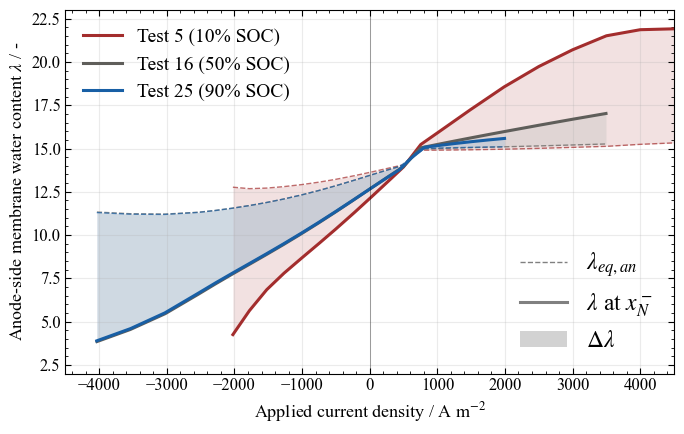

In [11]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
import numpy as np

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

custom = LinearSegmentedColormap.from_list("soc", ['#A32D2D', '#5F5E5A', '#185FA5'])
soc_colors = custom(np.linspace(0.0, 1.0, len(flux_sweep)))
test_labels = {5: "10% SOC", 16: "50% SOC", 25: "90% SOC"}

def lighten(color, amount=0.6):
    c = np.array(mcolors.to_rgb(color))
    return tuple(c + (1 - c) * amount)

fig, ax = plt.subplots(figsize=(7, 4.5))

for (TEST_NO, d), c in zip(flux_sweep.items(), soc_colors):
    order        = np.argsort(d["j"])
    j_sorted     = d["j"][order]
    lambda_b     = d["lambda_an"][order]      # boundary λ
    lambda_eq    = d["lambda_eq_an"][order]   # equilibrium λ at anode
    c_light      = lighten(c, 0.6)
    
    ax.fill_between(j_sorted, lambda_b, lambda_eq, color=c_light, alpha=0.35, linewidth=0)
    ax.plot(j_sorted, lambda_eq, lw=1.0, color=c, ls="--", alpha=0.7)
    ax.plot(j_sorted, lambda_b,  lw=2.2, color=c, ls="-")

ax.axvline(0, color="k", lw=0.6, alpha=0.4)
ax.set_xlabel(r"Applied current density / A m$^{-2}$")
ax.set_ylabel(r"Anode-side membrane water content $\lambda$ / -")
ax.grid(True, alpha=0.25)
ax.set_xlim(-4500, 4500)
ax.set_ylim(2, 23)

test_handles = [Line2D([0],[0], color=c, lw=2.2, label=f"Test {t} ({test_labels[t]})")
                for c, t in zip(soc_colors, flux_sweep.keys())]
style_handles = [
    Line2D([0],[0], color='gray', lw=1.0, ls='--', label=r'$\lambda_{eq,an}$'),
    Line2D([0],[0], color='gray', lw=2.2, ls='-',  label=r'$\lambda$ at $x_N^-$'),
    Patch(facecolor='gray', alpha=0.35, label=r'$\Delta\lambda$'),
]
leg1 = ax.legend(handles=test_handles, loc='upper left', fontsize=14, frameon=False)
ax.add_artist(leg1)
ax.legend(handles=style_handles, loc='lower right', fontsize=17, frameon=False)

plt.tight_layout()
out_path = ROOT / f"figures/boundary_membrane_an.pdf"
plt.savefig(out_path, dpi=600, bbox_inches='tight')
plt.show()


## Water-to-proton drag ratio $N_w/(i/F)$ vs. applied current density (tests 5, 16, 25)

For each test in `FLUX_SWEEP_TESTS`, divide the membrane net water flux $N_w$
(diffusion + EOD, same face values as the flux-balance plots above) by the molar
proton flux $i/F = j_{appl}/F$, at both the cathode-side and anode-side membrane
faces. Near $j_{appl}\to 0$ this ratio diverges (diffusion stays finite while the
EOD/proton-flux term vanishes), so the y-axis is clipped to the physically
informative range.

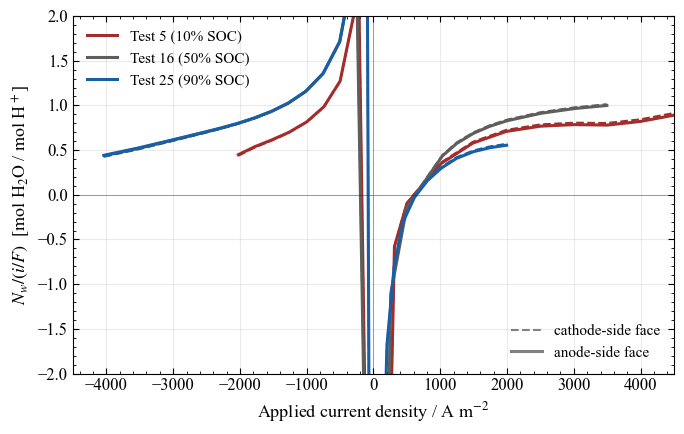

In [12]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
import numpy as np

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 13,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

custom = LinearSegmentedColormap.from_list("soc", ['#A32D2D', '#5F5E5A', '#185FA5'])
soc_colors = custom(np.linspace(0.0, 1.0, len(flux_sweep)))
test_labels = {5: "10% SOC", 16: "50% SOC", 25: "90% SOC"}

fig, ax = plt.subplots(figsize=(7, 4.5))

for (TEST_NO, d), c in zip(flux_sweep.items(), soc_colors):
    order    = np.argsort(d["j"])
    j_sorted = d["j"][order]
    ca       = d["Nw_over_iF_ca"][order]
    an       = d["Nw_over_iF_an"][order]

    ax.plot(j_sorted, ca, lw=1.5, ls="--", color=c)
    ax.plot(j_sorted, an, lw=2.2, ls="-",  color=c)

ax.axhline(0, color="k", lw=0.6, alpha=0.4)
ax.axvline(0, color="k", lw=0.6, alpha=0.4)
ax.set_xlabel(r"Applied current density / A m$^{-2}$")
ax.set_ylabel(r"$N_w/(i/F)$  [mol H$_2$O / mol H$^+$]")
ax.grid(True, alpha=0.25)
ax.set_xlim(-4500, 4500)
ax.set_ylim(-2, 2)

test_handles = [Line2D([0], [0], color=c, lw=2.2, label=f"Test {t} ({test_labels[t]})")
                for c, t in zip(soc_colors, flux_sweep.keys())]
style_handles = [
    Line2D([0], [0], color='gray', lw=1.5, ls='--', label='cathode-side face'),
    Line2D([0], [0], color='gray', lw=2.2, ls='-',  label='anode-side face'),
]
leg1 = ax.legend(handles=test_handles, loc='upper left', fontsize=11, frameon=False)
ax.add_artist(leg1)
ax.legend(handles=style_handles, loc='lower right', fontsize=11, frameon=False)

plt.tight_layout()
out_path = ROOT / "figures/Nw_over_iF_vs_j.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=600, bbox_inches='tight', pad_inches=0.05)
plt.show()

## Membrane water flux along thickness (test 5 only)

Decomposes the membrane water flux `N_w` (diffusion + EOD) at every internal mesh
face, from the cathode side (x=0) to the anode side (x=1), using the last simulated
state of test 5 from the `runs` dict above. Same face-flux formula as the boundary
faces in the flux-vs-j sweep, generalised to all internal faces (see the bulk/BC
blocks around lines 358-365 and 396-419 of `dae_residual_full_cell.py`).

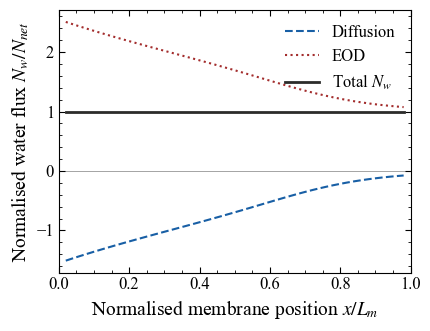

Diffusion -1.5070445500781047 -0.07499087567521384 EOD 2.507044550078105 1.0749908756752138 Total 1.0 1.0
0.049760224852893255


In [13]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 13,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 12,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.minor.size': 2,
    'ytick.minor.size': 2,
    'axes.linewidth': 0.8,
    'lines.linewidth': 1.2,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

TEST_FLUX_PROFILE = 5
r    = runs[TEST_FLUX_PROFILE]
cell = r["cell"]

# refresh self.i_io / self.bc at the last simulated state
y_last = r["ysol"][:, -1]
cell.dae_residual_full_cell(r["tsol"][-1], y_last, np.zeros_like(y_last))

lam = r["lambda_mem"][:, -1]
F, c_f, i_io = cell.F, cell.membrane.c_f, cell.i_io
dx_face_m    = cell._dx_face_m

lam_upwind = lam[:-1] if i_io > 0 else lam[1:]
D_face     = cell.membrane_water_diffusivity((lam[:-1] + lam[1:]) / 2, "hwang")
zeta_face  = cell.EOD_coefficient(lam_upwind)

J_diff  = -D_face * (lam[1:] - lam[:-1]) / dx_face_m
J_EOD   = zeta_face * i_io / (F * c_f)
J_total = J_diff + J_EOD

J_diff  = J_diff / J_total
J_EOD   = J_EOD / J_total
J_total = J_total / J_total

edges_m = np.concatenate([[0.0], np.cumsum(cell.mesh.membrane_mesh.dx)])
x_face  = edges_m[1:-1]

fig, ax = plt.subplots(figsize=(4.5, 3.5))

# Subtle palette: deep red for EOD, deep blue for diffusion, dark gray for total
ax.plot(x_face, J_diff,  lw=1.5, ls="--", color="#185FA5", label="Diffusion")
ax.plot(x_face, J_EOD,   lw=1.5, ls=":",  color="#A32D2D", label="EOD")
ax.plot(x_face, J_total, lw=2, ls="-",  color="#2C2C2A", label=r"Total $N_w$")

ax.axhline(0, color="k", lw=0.5, alpha=0.5)

ax.set_xlabel(r"Normalised membrane position $x/L_m$")
ax.set_ylabel(r"Normalised water flux $N_w/N_{net}$")
ax.set_xlim(0, 1)
ax.legend(frameon=False, loc='best')

plt.tight_layout()
out_path = ROOT / "figures/membrane_water_flux_profile_test5.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()


print("Diffusion", J_diff[0], J_diff[-1], "EOD", J_EOD[0], J_EOD[-1], "Total", J_total[0], J_total[-1])
print(J_diff[-1]/J_diff[0])

## Water-to-proton drag ratio $N_w/(i/F)$ along the membrane (from the cathode side)

Same test-5 last state as the cell above. $N_w$ (diffusion + EOD, in mol H$_2$O m$^{-2}$ s$^{-1}$)
is divided by the proton flux $i_{io}/F$ at each internal membrane face, giving the
net number of water molecules dragged per proton crossing the membrane, starting at
the cathode-side face ($x/L_m=0$) through to the anode-side face ($x/L_m=1$).

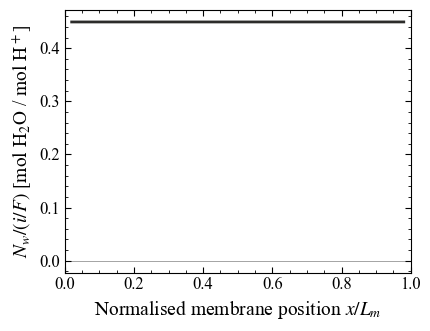

N_w/(i/F): min=0.4494  max=0.4494  at cathode-side face (x/L_m=0.020)=0.4494  at anode-side face (x/L_m=0.980)=0.4494


In [14]:
TEST_FLUX_PROFILE = 5
r    = runs[TEST_FLUX_PROFILE]
cell = r["cell"]

# refresh self.i_io / self.bc at the last simulated state
y_last = r["ysol"][:, -1]
cell.dae_residual_full_cell(r["tsol"][-1], y_last, np.zeros_like(y_last))

lam = r["lambda_mem"][:, -1]
F, c_f, i_io = cell.F, cell.membrane.c_f, cell.i_io
dx_face_m    = cell._dx_face_m

# face flux N_w, same formula as water_transport_residual.py (N_e/N_w terms),
# scaled by c_f to get molar water flux [mol H2O / (m2 s)]
lam_upwind = lam[:-1] if i_io > 0 else lam[1:]
D_face     = cell.membrane_water_diffusivity((lam[:-1] + lam[1:]) / 2, "hwang")
zeta_face  = cell.EOD_coefficient(lam_upwind)

N_w_lambda = -D_face * (lam[1:] - lam[:-1]) / dx_face_m + zeta_face * i_io / (F * c_f)
N_w        = c_f * N_w_lambda                 # molar water flux, mol/(m2 s)
i_over_F   = i_io / F                          # molar proton flux, mol/(m2 s)

Nw_over_iF = N_w / i_over_F                    # mol H2O dragged per mol H+

edges_m = np.concatenate([[0.0], np.cumsum(cell.mesh.membrane_mesh.dx)])
x_face  = edges_m[1:-1]

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.plot(x_face, Nw_over_iF, lw=2, color="#2C2C2A")
ax.axhline(0, color="k", lw=0.5, alpha=0.5)
ax.set_xlabel(r"Normalised membrane position $x/L_m$")
ax.set_ylabel(r"$N_w/(i/F)$ [mol H$_2$O / mol H$^+$]")
ax.set_xlim(0, 1)

plt.tight_layout()
out_path = ROOT / "figures/Nw_over_iF_profile_test5.pdf"
out_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_path, dpi=600, bbox_inches="tight", pad_inches=0.05)
plt.show()

print(f"N_w/(i/F): min={Nw_over_iF.min():.4f}  max={Nw_over_iF.max():.4f}  "
      f"at cathode-side face (x/L_m={x_face[0]:.3f})={Nw_over_iF[0]:.4f}  "
      f"at anode-side face (x/L_m={x_face[-1]:.3f})={Nw_over_iF[-1]:.4f}")